17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 64)   │    640,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 200, 128)  │     66,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 128),     │      8,320 │ bidirectional[0]… │
│ (AttentionLayer)    │ (None, 200)]      │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      4,128 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 718,529 (2.74 MB)

 Trainable params: 718,529 (2.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 125s 767ms/step - accuracy: 0.7775 - loss: 0.4568 - val_accuracy: 0.8508 - val_loss: 0.3365
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 118s 749ms/step - accuracy: 0.8996 - loss: 0.2538 - val_accuracy: 0.8720 - val_loss: 0.3070
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 117s 748ms/step - accuracy: 0.9239 - loss: 0.2009 - val_accuracy: 0.8370 - val_loss: 0.3929
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 116s 741ms/step - accuracy: 0.9401 - loss: 0.1608 - val_accuracy: 0.8718 - val_loss: 0.3513
196/196 ━━━━━━━━━━━━━━━━━━━━ 41s 211ms/step - accuracy: 0.8523 - loss: 0.3410
Test loss: 0.3410 | Test accuracy: 0.8523
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review #0 | True: NEG | Pred: NEG (0.111)
Top attended words: [('the', 0.046), ('rest', 0.044), ('br', 0.043), ('and', 0.042), ('br', 0.042), ('<unk>', 0.041), ('rendered', 0.04), ('<unk>', 0.04)]


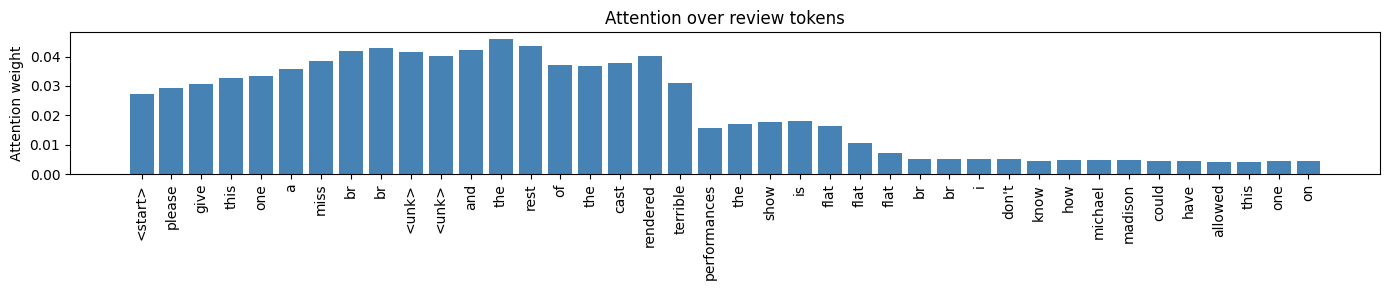

Review #1 | True: POS | Pred: POS (0.995)
Top attended words: [('of', 0.004), ('the', 0.004), ('many', 0.004), ('place', 0.003), ('the', 0.003), ('on', 0.003), ('scenes', 0.003), ('take', 0.003)]


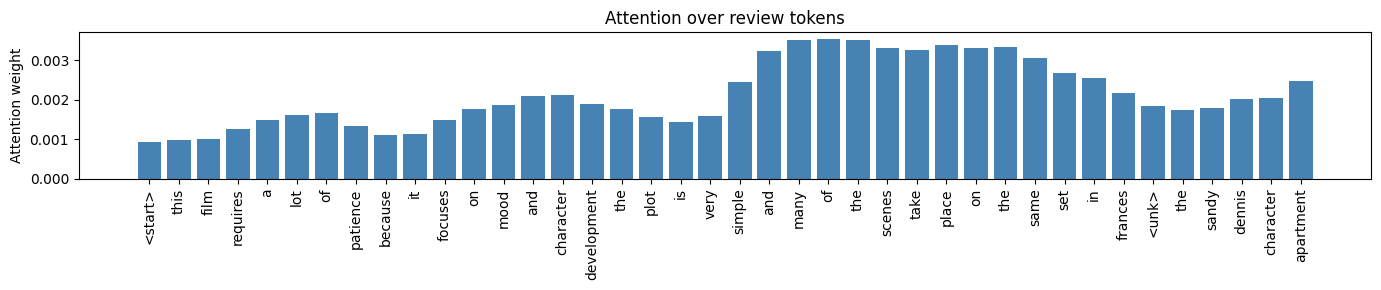

Review #2 | True: POS | Pred: POS (0.916)
Top attended words: [('almost', 0.006), ('it', 0.006), ('happened', 0.005), ('invented', 0.005), ('interested', 0.005), ('animation', 0.005), ('a', 0.005), ('which', 0.005)]


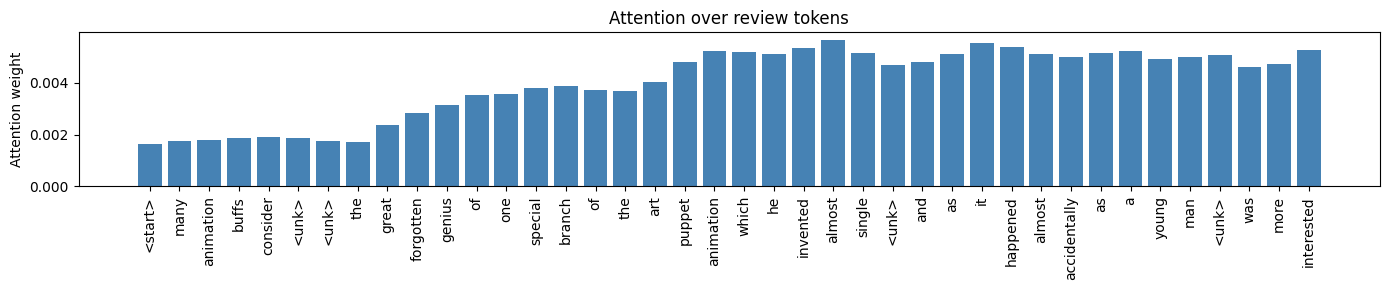

this movie was absolutely fantastic and I loved it -> POSITIVE (0.899) | most attended: 'it'
terrible plot and awful acting a complete waste of time -> NEGATIVE (0.002) | most attended: 'terrible'


In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Settings
VOCAB_SIZE = 10000
MAX_LEN = 200
EMBED_DIM = 64
BATCH_SIZE = 128
EPOCHS = 5

# Data
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
x_train = pad_sequences(x_train, maxlen=MAX_LEN, padding="post", truncating="post")
x_test  = pad_sequences(x_test,  maxlen=MAX_LEN, padding="post", truncating="post")


# Custom additive (Bahdanau-style) attention layer
class AttentionLayer(layers.Layer):
    """
    score_t   = v^T tanh(W h_t)
    alpha_t   = softmax(score_t)           (over time steps, padding masked out)
    context   = sum_t alpha_t * h_t
    Returns (context_vector, attention_weights)
    """
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True
        self.W = layers.Dense(units, activation="tanh")
        self.v = layers.Dense(1, use_bias=False)

    def call(self, inputs, mask=None):
        score = self.v(self.W(inputs))                        # (batch, time, 1)
        if mask is not None:
            mask = tf.cast(mask, score.dtype)[:, :, tf.newaxis]
            score += (1.0 - mask) * -1e9                      # ignore padded steps
        weights = tf.nn.softmax(score, axis=1)                # (batch, time, 1)
        context = tf.reduce_sum(weights * inputs, axis=1)     # (batch, features)
        return context, tf.squeeze(weights, axis=-1)

    def compute_mask(self, inputs, mask=None):
        return None

    def get_config(self):
        config = super().get_config()
        config.update({"units": self.units})
        return config


# Model: Embedding -> BiLSTM (return sequences) -> Attention -> Dense
inputs = layers.Input(shape=(MAX_LEN,))
x = layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True)(inputs)
x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
context, attn_weights = AttentionLayer(units=64, name="attention")(x)
x = layers.Dropout(0.5)(context)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)
attention_model = models.Model(inputs, attn_weights)   # shares weights, used for visualization

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

# Train
early_stop = callbacks.EarlyStopping(monitor="val_accuracy", patience=2,
                                     restore_best_weights=True)
history = model.fit(x_train, y_train, validation_split=0.2,
                    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[early_stop])

# Evaluate
loss, acc = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE)
print(f"Test loss: {loss:.4f} | Test accuracy: {acc:.4f}")

# Decode reviews back to words
word_index = imdb.get_word_index()
index_word = {v + 3: k for k, v in word_index.items()}
index_word.update({0: "<pad>", 1: "<start>", 2: "<unk>", 3: "<unk>"})

def decode(seq):
    return [index_word.get(i, "<unk>") for i in seq]

# Visualize attention for a test review
def show_attention(idx, max_words=40):
    seq = x_test[idx:idx + 1]
    prob = model.predict(seq, verbose=0)[0][0]
    weights = attention_model.predict(seq, verbose=0)[0]

    n = int((seq[0] != 0).sum())                  # real (non-padded) length
    words = decode(seq[0][:n])[:max_words]
    w = weights[:len(words)]

    print(f"Review #{idx} | True: {'POS' if y_test[idx] else 'NEG'} | "
          f"Pred: {'POS' if prob > 0.5 else 'NEG'} ({prob:.3f})")
    top = np.argsort(w)[::-1][:8]
    print("Top attended words:", [(words[i], round(float(w[i]), 3)) for i in top])

    plt.figure(figsize=(14, 3))
    plt.bar(range(len(words)), w, color="steelblue")
    plt.xticks(range(len(words)), words, rotation=90)
    plt.ylabel("Attention weight")
    plt.title("Attention over review tokens")
    plt.tight_layout()
    plt.show()

for i in [0, 1, 2]:
    show_attention(i)

# Predict on custom text
def encode(text):
    tokens = [word_index.get(w, -1) + 3 for w in text.lower().split()]
    tokens = [t if 3 <= t < VOCAB_SIZE else 2 for t in tokens]
    return pad_sequences([tokens], maxlen=MAX_LEN, padding="post", truncating="post")

for text in ["this movie was absolutely fantastic and I loved it",
             "terrible plot and awful acting a complete waste of time"]:
    seq = encode(text)
    prob = model.predict(seq, verbose=0)[0][0]
    w = attention_model.predict(seq, verbose=0)[0]
    words = text.lower().split()
    best = words[int(np.argmax(w[:len(words)]))]
    print(f"{text} -> {'POSITIVE' if prob > 0.5 else 'NEGATIVE'} ({prob:.3f}) | most attended: '{best}'")

# Save (custom layer must be passed when loading)
model.save("attention_imdb.keras")
# model = tf.keras.models.load_model("attention_imdb.keras",
#                                    custom_objects={"AttentionLayer": AttentionLayer})